<a href="https://colab.research.google.com/github/bayuaripermana/bayuaripermana/blob/main/01_Data_Cleaning_Review_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import re
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries successfully imported!")

Libraries successfully imported!


In [3]:
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("File:", file_name)

Saving Dataset Review Product di Shopee dan Tokopedia.csv to Dataset Review Product di Shopee dan Tokopedia (1).csv
File: Dataset Review Product di Shopee dan Tokopedia (1).csv


In [4]:
# ==========================================
# 2. LOAD DATASET
# ==========================================

df_raw = pd.read_csv(
    file_name,
    sep=';',
    encoding='cp1252'
)

# Salinan untuk proses cleaning
df = df_raw.copy()

print("Dataset successfully loaded!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset successfully loaded!
Rows: 68346
Columns: 3


,review_id,review,rating
0,0,slow delivery,1
1,1,Dateng goods do not conform pesanan??,1
2,2,PSN k its 20 other DTG,1
3,3,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,1
4,4,The product quality is not good.,1


In [5]:
# ==========================================
# 3. DATA PROFILING
# ==========================================

print("DATASET INFORMATION")
print("===================")

df.info()

print("\nDATASET DIMENSION")
print(df.shape)

print("\nSTATISTICAL SUMMARY")
display(df.describe(include='all').T)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68346 entries, 0 to 68345
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review_id  68346 non-null  int64 
 1   review     68041 non-null  object
 2   rating     68346 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.6+ MB

DATASET DIMENSION
(68346, 3)

STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,68346.0,NaN,NaN,NaN,29175.588637,19086.666812,0.0,11658.25,28744.5,45830.75,62917.0
review,68041,54406,Excellent product quality,617,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,68346.0,NaN,NaN,NaN,3.662233,1.268905,1.0,3.0,4.0,5.0,5.0



COLUMN NAMES
['review_id', 'review', 'rating']


In [6]:
# ==========================================
# DATA QUALITY PROFILE
# ==========================================

profile = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Non-Null': df.notna().sum(),
    'Missing': df.isna().sum(),
    'Missing (%)': (
        df.isna().mean() * 100
    ).round(2),
    'Unique Values': df.nunique()
})

display(profile)

,Data Type,Non-Null,Missing,Missing (%),Unique Values
review_id,int64,68346,0,0.00,62918
review,object,68041,305,0.45,54406
rating,int64,68346,0,0.00,5


In [7]:
# ==========================================
# 4. MISSING VALUES ANALYSIS
# ==========================================

# Mengidentifikasi string kosong
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].replace(
        r'^\s*$',
        np.nan,
        regex=True
    )

missing_report = pd.DataFrame({
    'Missing Values': df.isna().sum(),
    'Percentage (%)': (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing Values,Percentage (%)
review_id,0,0.00
review,305,0.45
rating,0,0.00


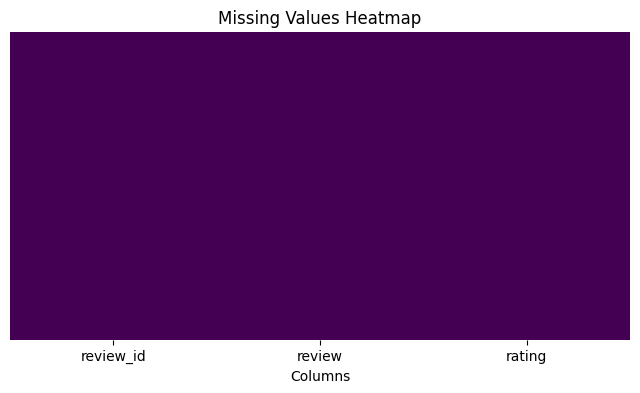

In [8]:
plt.figure(figsize=(8, 4))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.xlabel('Columns')
plt.show()

In [9]:
# ==========================================
# 5A. FULL ROW DUPLICATES
# ==========================================

full_duplicates = df.duplicated().sum()

print("Full Duplicate Rows:", full_duplicates)

Full Duplicate Rows: 0


In [10]:
# ==========================================
# 5B. DUPLICATE REVIEW ID
# ==========================================

duplicate_ids = df[
    df.duplicated(
        subset=['review_id'],
        keep=False
    )
].sort_values('review_id')

print("Duplicate ID Records:", len(duplicate_ids))

display(duplicate_ids.head(20))

Duplicate ID Records: 10856


,review_id,review,rating
0,0,slow delivery,1
62918,0,maaantap,5
62919,1,Enak & segar,5
1,1,Dateng goods do not conform pesanan??,1
2,2,PSN k its 20 other DTG,1
62920,2,maknyus,5
62921,3,Dari berat 500 gram yg remuk 59 gram.\nEntah dari awal packing atau expedisi.\nUntuk masukan aja...,4
3,3,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,1
62922,4,"enak banget, fresh dan renyah!",5
4,4,The product quality is not good.,1


In [11]:
# ==========================================
# 5C. DUPLICATE REVIEW TEXT
# ==========================================

duplicate_reviews = df[
    df['review'].notna() &
    df['review'].duplicated(keep=False)
].sort_values('review')

print("Duplicate Review Records:", len(duplicate_reviews))

display(duplicate_reviews.head(20))

Duplicate Review Records: 14926


,review_id,review,rating
45335,45335,"Excellent product quality, delivery speed is very good, very good seller's response",5
39577,39577,"Excellent product quality, delivery speed is very good, very good seller's response",4
50304,50304,"Excellent product quality, product price is very good, delivery speed is very good, very good s...",5
58281,58281,"Excellent product quality, product price is very good, delivery speed is very good, very good s...",5
31728,31728,"Excellent product quality, product price is very good, delivery speed is very good, very good s...",4
28210,28210,"Excellent product quality, product price is very good, delivery speed is very good, very good s...",4
51028,51028,"Excellent product quality, product price is very good, delivery speed is very good, very good s...",5
28799,28799,"Excellent product quality, product price is very good, very good delivery speed",4
42962,42962,"Excellent product quality, product price is very good, very good delivery speed",4
22690,22690,"Fair value Fast delivery, good.",3


In [12]:
# Mengelompokkan review berdasarkan teks
review_rating_check = (
    df.dropna(subset=['review'])
    .groupby('review')['rating']
    .nunique()
)

# Review yang memiliki lebih dari satu rating
conflicting_reviews = review_rating_check[
    review_rating_check > 1
]

print(
    "Identical Reviews With Different Ratings:",
    len(conflicting_reviews)
)

Identical Reviews With Different Ratings: 598


In [13]:
# ==========================================
# 6. RATING VALIDATION
# ==========================================

df['rating'] = pd.to_numeric(
    df['rating'],
    errors='coerce'
)

invalid_rating = df[
    ~df['rating'].between(1, 5) |
    df['rating'].isna() |
    (df['rating'] % 1 != 0)
]

print("Invalid Rating Records:", len(invalid_rating))

display(invalid_rating.head(20))

Invalid Rating Records: 0


,review_id,review,rating


,count
rating,
1,6404
2,5501
3,15536
4,18240
5,22665


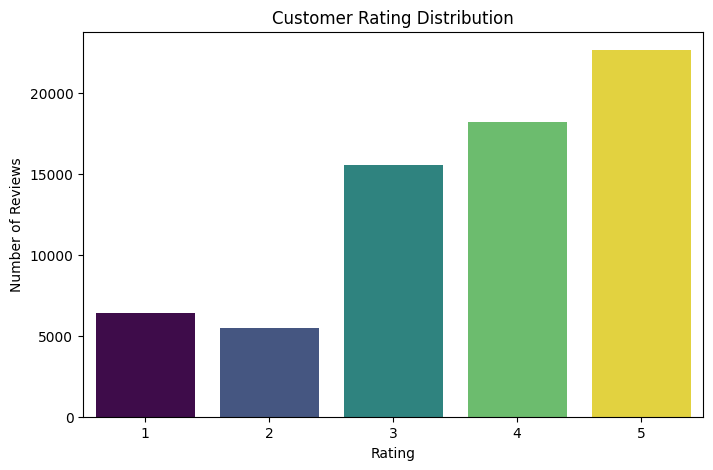

In [14]:
rating_distribution = (
    df['rating']
    .value_counts()
    .sort_index()
)

display(rating_distribution)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='rating',
    hue='rating',
    palette='viridis',
    legend=False
)

plt.title('Customer Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')

plt.show()

In [15]:
# ==========================================
# 7. TEXT CLEANING
# ==========================================

def clean_review(text):

    if pd.isna(text):
        return np.nan

    # Unicode normalization
    text = unicodedata.normalize('NFKC', str(text))

    # Menghapus karakter kontrol
    text = ''.join(
        char for char in text
        if unicodedata.category(char) != 'Cc'
        or char in '\n\t'
    )

    # Mengganti line breaks dan tab dengan spasi
    text = re.sub(r'\s+', ' ', text)

    # Menghilangkan spasi awal dan akhir
    text = text.strip()

    return text if text else np.nan


# Membuat kolom baru
df['review_clean'] = df['review'].apply(clean_review)

# Versi lowercase untuk analisis teks
df['review_lower'] = df['review_clean'].str.lower()

display(
    df[['review', 'review_clean', 'review_lower']].head(15)
)

,review,review_clean,review_lower
0,slow delivery,slow delivery,slow delivery
1,Dateng goods do not conform pesanan??,Dateng goods do not conform pesanan??,dateng goods do not conform pesanan??
2,PSN k its 20 other DTG,PSN k its 20 other DTG,psn k its 20 other dtg
3,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,i am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...
4,The product quality is not good.,The product quality is not good.,the product quality is not good.
5,"goods came really not the same as shown in the description, which is straight all, why ?, I want...","goods came really not the same as shown in the description, which is straight all, why ?, I want...","goods came really not the same as shown in the description, which is straight all, why ?, i want..."
6,Q order came quickly but im so very disappointed! Larger size n i u dineliver compared before! ?...,Q order came quickly but im so very disappointed! Larger size n i u dineliver compared before! ?...,q order came quickly but im so very disappointed! larger size n i u dineliver compared before! ?...
7,Aprox 1 bjunyaa,Aprox 1 bjunyaa,aprox 1 bjunyaa
8,"Send a brown color to black, very sick.","Send a brown color to black, very sick.","send a brown color to black, very sick."
9,Did not receive item Will not order again,Did not receive item Will not order again,did not receive item will not order again


In [16]:
# ==========================================
# 8. DATA QUALITY FLAGS
# ==========================================

# Menandai review kosong
df['is_missing_review'] = df['review_clean'].isna()

# Menandai review ID yang berulang
df['is_duplicate_id'] = df.duplicated(
    subset=['review_id'],
    keep=False
)

# Menandai teks review yang berulang
df['is_duplicate_review'] = (
    df['review_clean'].notna() &
    df['review_clean'].duplicated(keep=False)
)

# Menandai rating tidak valid
df['is_invalid_rating'] = (
    ~df['rating'].between(1, 5) |
    df['rating'].isna() |
    (df['rating'] % 1 != 0)
)

display(df.head())

,review_id,review,rating,review_clean,review_lower,is_missing_review,is_duplicate_id,is_duplicate_review,is_invalid_rating
0,0,slow delivery,1,slow delivery,slow delivery,False,True,True,False
1,1,Dateng goods do not conform pesanan??,1,Dateng goods do not conform pesanan??,dateng goods do not conform pesanan??,False,True,False,False
2,2,PSN k its 20 other DTG,1,PSN k its 20 other DTG,psn k its 20 other dtg,False,True,False,False
3,3,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,1,I am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,i am expected that it have a frame and painted in a canvass but sad to note i am very disappoint...,False,True,False,False
4,4,The product quality is not good.,1,The product quality is not good.,the product quality is not good.,False,True,True,False


In [17]:
# ==========================================
# 9. FINAL VALIDATION
# ==========================================

final_report = pd.DataFrame({
    'Check': [
        'Total Records',
        'Missing Review',
        'Duplicate Full Rows',
        'Duplicate Review ID Records',
        'Duplicate Review Text Records',
        'Invalid Ratings',
        'Valid Ratings'
    ],

    'Results': [
        len(df),
        df['review_clean'].isna().sum(),
        df.duplicated().sum(),
        df['is_duplicate_id'].sum(),
        df['is_duplicate_review'].sum(),
        df['is_invalid_rating'].sum(),
        df['rating'].between(1, 5).sum()
    ]
})

display(final_report)

,Check,Results
0,Total Records,68346
1,Missing Review,305
2,Duplicate Full Rows,0
3,Duplicate Review ID Records,10856
4,Duplicate Review Text Records,15038
5,Invalid Ratings,0
6,Valid Ratings,68346


In [18]:
# ==========================================
# 10. EXPORT DATA
# ==========================================

# Dataset hasil cleaning
df_cleaned = df.copy()

# Dataset siap untuk analisis teks
df_analysis = df_cleaned[
    df_cleaned['review_clean'].notna() &
    df_cleaned['rating'].between(1, 5) &
    (df_cleaned['rating'] % 1 == 0)
].copy()

# Export CSV
df_cleaned.to_csv(
    'Retail_Reviews_Cleaned.csv',
    index=False,
    encoding='utf-8-sig'
)

df_analysis.to_csv(
    'Retail_Reviews_Analysis_Ready.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Export completed!")
print("Cleaned Dataset:", df_cleaned.shape)
print("Analysis Ready:", df_analysis.shape)

Export completed!
Cleaned Dataset: (68346, 9)
Analysis Ready: (68041, 9)


In [19]:
from google.colab import files

files.download('Retail_Reviews_Cleaned.csv')
files.download('Retail_Reviews_Analysis_Ready.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>